[![Homepage](https://img.shields.io/badge/homepage-blueviolet?logo=htmx)](https://www.bendai.org/CUHK-STAT3009/)
[![GitHub](https://img.shields.io/badge/GitHub-black.svg?logo=github)](https://github.com/statmlben/CUHK-STAT3009)
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/statmlben/CUHK-STAT3009/blob/main/nb/STAT3009_ML_II.ipynb)

# Notebook 04: Machine Learning II — Generalization and model selection

**STAT3009 · Recommender Systems**  
**Suggested time:** 105–120 minutes of guided coding and discussion

ML I showed how to fit a model and calculate RMSE. This notebook asks a different question: **how do we choose a model setting without using the final test answers?**

```text
training data → holdout / cross-validation → choose hyperparameters
              → refit on all training data → evaluate once on test
```

We use the same two examples as the ML II slides: Ridge regression on California housing, then weighted three-mean prediction on the course's binary rating split. By the end, you should be able to:

1. distinguish fitting, validation, and final test roles;
2. identify Ridge's model, hyperparameter, fitting criterion, and learned parameters;
3. select `alpha` with `GridSearchCV` and read its results;
4. diagnose training and validation error across Ridge settings;
5. choose a rating-data split, then use `GridSearchCV` to select three-mean weights without leakage.

## 1. Setup

We reuse the libraries and RMSE metric from ML I. The new tools are `Ridge`, `train_test_split`, and `GridSearchCV`.

In [1]:
import random

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.linear_model import Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.utils.validation import check_is_fitted

pd.set_option('display.max_rows', 12)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

## 2. Ridge: the four questions

ML I used linear regression for California housing. Ridge keeps the same prediction rule but changes how the coefficients are fitted.

| Question | Ridge answer |
|---|---|
| **Model** | $\widehat y=b+x^{\mathsf T}w$ |
| **Hyperparameter** | $\alpha\geq0$, chosen *before* fitting |
| **Fitting criterion** | $\displaystyle\min_{b,w}\sum_{j=1}^{n}(y_j-b-x_j^{\mathsf T}w)^2+\alpha\lVert w\rVert_2^2$ |
| **Learned parameters** | $\widehat b$ and $\widehat w$, stored as `intercept_` and `coef_` after `fit` |

The penalty acts on $w$, not the intercept $b$. Training loss helps fit $b,w$ for one `alpha`; **validation RMSE** helps us choose among different `alpha` values. [Ridge documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html).

### Reload the housing split from ML I

This notebook runs independently, so we reload the same fixed course split. The test arrays stay out of all model-selection cells.

In [2]:
HOUSING_BASE_URL = (
    'https://raw.githubusercontent.com/'
    'statmlben/CUHK-STAT3009/main/dataset/housing'
)

housing_train = pd.read_csv(f'{HOUSING_BASE_URL}/train.csv')
housing_test = pd.read_csv(f'{HOUSING_BASE_URL}/test.csv')

feature_columns = [
    'MedInc', 'HouseAge', 'AveRooms', 'AveBedrms',
    'Population', 'AveOccup', 'Latitude', 'Longitude',
]

X_train_housing = housing_train[feature_columns].to_numpy(dtype=float)
y_train_housing = housing_train['MedHouseVal'].to_numpy(dtype=float)
X_test_housing = housing_test[feature_columns].to_numpy(dtype=float)
y_test_housing = housing_test['MedHouseVal'].to_numpy(dtype=float)

print('training rows:', len(y_train_housing))
print('test rows:', len(y_test_housing))
print('features:', X_train_housing.shape[1])

training rows: 13828
test rows: 6812
features: 8


### One fit, one prediction

Changing `alpha` creates a different fitted model. Compare the constructor setting with the attributes learned from training rows.

In [3]:
ridge_demo = Ridge(alpha=1.0)
print('alpha before fit:', ridge_demo.get_params()['alpha'])

ridge_demo.fit(X_train_housing, y_train_housing)
print('intercept_ after fit:', ridge_demo.intercept_)
print('coef_ after fit:', ridge_demo.coef_)
print('first three predictions:', ridge_demo.predict(X_train_housing[:3]))

alpha before fit: 1.0
intercept_ after fit: -37.07723507863211
coef_ after fit: [ 4.44680986e-01  9.55214617e-03 -1.21631134e-01  7.77130987e-01
 -7.19191084e-08 -3.29891634e-03 -4.19121631e-01 -4.34068358e-01]
first three predictions: [1.12200039 2.55553736 2.32332033]


### Checkpoint

If we change `alpha` from `1` to `100`, which value is chosen by us, and which values must be learned again? Why is training RMSE alone insufficient to choose `alpha`?

## 3. Holdout validation

Use only the **training** rows from the course split. `train_test_split` creates a smaller fitting set and a temporary validation set. Each candidate `alpha` is fitted from the same fitting rows and evaluated on the same validation rows.

In [4]:
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train_housing,
    y_train_housing,
    test_size=0.25,
    random_state=42,
)

print('fit rows:', len(y_fit))
print('validation rows:', len(y_valid))
print('final test rows, still untouched:', len(y_test_housing))

fit rows: 10371
validation rows: 3457
final test rows, still untouched: 6812


In [5]:
alpha_candidates = [0.1, 1.0, 100.0]
holdout_rows = []

for alpha in alpha_candidates:
    model = Ridge(alpha=alpha)
    model.fit(X_fit, y_fit)

    train_rmse = root_mean_squared_error(
        y_fit, model.predict(X_fit)
    )
    valid_rmse = root_mean_squared_error(
        y_valid, model.predict(X_valid)
    )
    holdout_rows.append({
        'alpha': alpha,
        'fit RMSE': train_rmse,
        'validation RMSE': valid_rmse,
    })

holdout_results = pd.DataFrame(holdout_rows)
display(holdout_results.sort_values('validation RMSE'))

,alpha,fit RMSE,validation RMSE
2,100.0000,0.7231,0.7181
1,1.0000,0.7221,0.7189
0,0.1000,0.7221,0.7190


### Discuss

1. Which `alpha` has the lowest **validation** RMSE? Does it also have the lowest fitting RMSE?
2. Would the ranking necessarily stay the same if we changed `random_state`? A single split can be noisy.
3. Did any test answer enter the table above?

## 4. Five-fold CV with `GridSearchCV`

Cross-validation rotates which training block acts as validation. For each `alpha`, `GridSearchCV` fits five times and averages five validation scores. `refit=True` then fits the winning `alpha` once more on **all** housing training rows. [GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).

Scikit-learn **maximizes** scores, so its RMSE scorer is named `neg_root_mean_squared_error`. Change the sign back when reading `best_score_` or `mean_test_score`.

### Your turn: run a Ridge search

Fill in the candidate list, metric, and CV count. Use the **course training split**, not `X_fit` or the final test set. Then compare your cell with the solution below.

In [6]:
# ridge_search = GridSearchCV(
#     estimator=Ridge(),
#     param_grid={'alpha': [...]},       # 0.1, 1.0, 100.0
#     scoring='...',                     # negative RMSE scorer
#     cv=...,                            # five folds
#     refit=True,
# )
# ridge_search.fit(X_train_housing, y_train_housing)

### Solution

In [7]:
ridge_search = GridSearchCV(
    estimator=Ridge(),
    param_grid={'alpha': [0.1, 1.0, 100.0]},
    scoring='neg_root_mean_squared_error',
    cv=5,
    refit=True,  #it then automatically re-fits a final Ridge model using that best alpha on the entire X_train_housing / y_train_housing.
)
ridge_search.fit(X_train_housing, y_train_housing)

ridge_cv_results = pd.DataFrame({
    'alpha': ridge_search.cv_results_['param_alpha'],
    'CV RMSE': -ridge_search.cv_results_['mean_test_score'],
})
display(ridge_cv_results.sort_values('CV RMSE'))

,alpha,CV RMSE
0,0.1000,0.7231
1,1.0000,0.7231
2,100.0000,0.7240


### Read the selected estimator

`best_params_` gives the chosen **hyperparameter**. `best_score_` summarizes validation performance. `best_estimator_` contains coefficients learned by the **final refit**; they are not one fold's coefficients.

In [8]:
print('chosen alpha:', ridge_search.best_params_['alpha'])
print(f'five-fold CV RMSE: {-ridge_search.best_score_:.4f}')

final_ridge = ridge_search.best_estimator_
print('final model alpha:', final_ridge.alpha)
print('final model intercept_:', final_ridge.intercept_)
print('final model coef_ shape:', final_ridge.coef_.shape)

chosen alpha: 0.1
five-fold CV RMSE: 0.7231
final model alpha: 0.1
final model intercept_: -37.08153452089047
final model coef_ shape: (8,)


### Diagnostic: fitting error versus CV error

The slide's curve uses **200 rows sampled from the housing training data** so that the fitting–validation gap is visible. This is a diagnostic example, **not** the full-data search that chose `final_ridge` above. The final test rows remain untouched.

We ask `GridSearchCV` for its optional training-fold scores with `return_train_score=True`. The same negative-RMSE sign convention applies to both training and validation columns. `refit=False` is appropriate here because we only want to inspect the curve; the earlier full-data search already refitted its winner.

,alpha,fit-fold RMSE,validation-fold RMSE
0,0.1000,0.6818,0.8039
1,1.0000,0.6821,0.8021
2,10.0000,0.6906,0.7897
3,100.0000,0.7506,0.7802
4,1000.0000,0.9346,0.9444
5,10000.0000,1.1625,1.1686
6,100000.0000,1.2218,1.2252


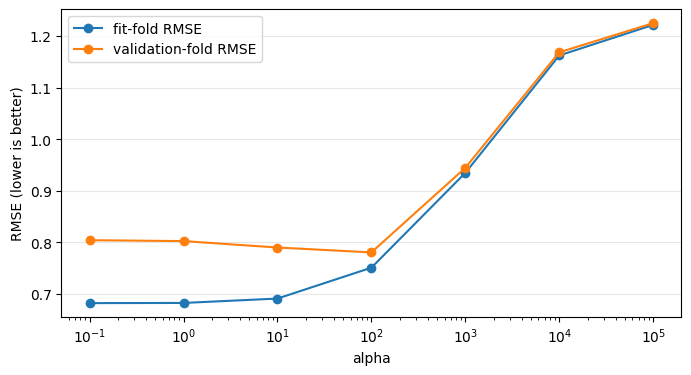

In [9]:
import matplotlib.pyplot as plt

demo_rows = random.Random(42).sample(range(len(y_train_housing)), 200)
X_demo = X_train_housing[demo_rows]
y_demo = y_train_housing[demo_rows]

curve_search = GridSearchCV(
    estimator=Ridge(),
    param_grid={'alpha': [0.1, 1, 10, 100, 1000, 10000, 100000]},
    scoring='neg_root_mean_squared_error',
    cv=5,
    refit=False,
    return_train_score=True,
)
curve_search.fit(X_demo, y_demo)

curve_results = pd.DataFrame({
    'alpha': np.asarray(curve_search.cv_results_['param_alpha'], dtype=float),
    'fit-fold RMSE': -curve_search.cv_results_['mean_train_score'],
    'validation-fold RMSE': -curve_search.cv_results_['mean_test_score'],
})
display(curve_results)

ax = curve_results.plot(
    x='alpha', y=['fit-fold RMSE', 'validation-fold RMSE'],
    marker='o', logx=True, figsize=(8, 4),
)
ax.set_ylabel('RMSE (lower is better)')
ax.grid(axis='y', alpha=0.3)
plt.show()

### Discuss the curve

1. Which `alpha` gives the smallest **fitting** RMSE? Which gives the smallest **validation** RMSE in this diagnostic sample?
2. What happens to both errors when `alpha` becomes very large?
3. Why should we **not** replace the earlier full-data `final_ridge` with this 200-row diagnostic model?

A CV curve need not always have a U shape. Read the measured values before drawing a conclusion.

**1. Smallest errors on this diagnostic sample**

- Smallest **fitting-fold RMSE**: \(\alpha = 0.1\) (0.6818)  
- Smallest **validation-fold RMSE**: \(\alpha = 100\) (0.7802)

**2. Behaviour as \(\alpha\) becomes very large**

Both the fit-fold and validation-fold RMSE rise sharply and converge toward each other.  
Heavy regularisation forces the coefficients toward zero, so the model essentially predicts the global mean. Bias becomes large and the two errors become almost identical (classic under-fitting).

**3. Why we must not replace the earlier full-data `final_ridge` with this 200-row model**

The curve was produced on a deliberately tiny random subset (200 rows) solely to make the fitting–validation gap visible.  
The earlier search that produced `final_ridge` used the **entire** training set, selected its best \(\alpha\), and refitted on all of those rows.  
Swapping in the diagnostic model would discard most of the available data and yield a substantially worse predictor. The 200-row exercise is only for illustration; the production model stays the full-data one.

### Final housing evaluation

The choice is now fixed. Predict the separate test rows and report RMSE once. The housing target is measured in units of $100{,}000$.

In [10]:
housing_test_pred = final_ridge.predict(X_test_housing)
housing_test_rmse = root_mean_squared_error(
    y_test_housing, housing_test_pred
)
print(f'final housing test RMSE: {housing_test_rmse:.4f}')

final housing test RMSE: 0.7328


## 5. Transfer the workflow to three-mean recommendation

We now choose the weights of the three-mean predictor from ML I:

$$\widehat r_{ui}=w_u\bar r_u+w_i\bar r_i+w_0\mu,\qquad w_u+w_i+w_0=1.$$

The **three means** are learned from ratings in each fitting fold. The **weights** are chosen by validation. If a validation pair has an unseen user or item, that missing mean uses the fitting fold's global mean.

We use `dataset/b-rs/train.csv`, the same **0/1 binary rating** split used for the slide's weight-comparison table. The earlier Netflix example used 1–5 ratings; the prediction rule is the same, but the RMSE scale is different. These IDs are already integer-coded, so no new encoding step is needed.

In [11]:
RS_BASE_URL = (
    'https://raw.githubusercontent.com/'
    'statmlben/CUHK-STAT3009/main/dataset/b-rs'
)

rs_train = pd.read_csv(f'{RS_BASE_URL}/train.csv')
X_train_rs = rs_train[['user_id', 'movie_id']].to_numpy(dtype=int)
y_train_rs = rs_train['rating'].to_numpy(dtype=float)

print('training ratings:', len(y_train_rs))
print('X shape:', X_train_rs.shape)
print('observed rating values:', sorted(set(y_train_rs.tolist())))
display(rs_train[['user_id', 'movie_id', 'rating']].head())

training ratings: 51161
X shape: (51161, 2)
observed rating values: [0.0, 1.0]


,user_id,movie_id,rating
0,1960,670,1
1,1346,152,1
2,785,1741,1
3,686,3032,1
4,1894,536,1


### Which validation question are we asking?

A **pair-level** split tests new user–item pairs. The slides show that 97.5% of the first fold's validation ratings involve a known user and a known item, so its overall RMSE mostly describes warm pairs. To evaluate entirely new users or items, we would hold out whole users or whole items instead.

Today we compare weights for the pair-level question. `GridSearchCV(cv=5)` will make the five folds, fit fresh means inside each fitting fold, and score the held-out ratings. We do not need to inspect fold indices by hand.

### Supply a three-mean estimator to sklearn

ML I introduced estimators with `fit` and `predict`. Here the constructor holds the **weights**; `fit` learns the three means from whichever fitting rows it receives; `predict` combines those means and falls back to the fitting-fold global mean for unseen IDs. `GridSearchCV` can therefore create a fresh fitted copy for each candidate and fold.

This class is supplied setup code. Focus on how the same `GridSearchCV` call used for Ridge now searches `weights`; you do not need to rewrite the fitting loop.

In [12]:
class ThreeMeanRS(RegressorMixin, BaseEstimator):
    def __init__(self, weights=(1/3, 1/3, 1/3)):
        self.weights = weights

    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y, dtype=float)
        users, items = X[:, 0].astype(int), X[:, 1].astype(int)

        self.global_mean_ = y.mean()
        self.user_means_ = np.full(users.max() + 1, self.global_mean_)
        self.item_means_ = np.full(items.max() + 1, self.global_mean_)

        for user in set(users):
            self.user_means_[user] = y[users == user].mean()
        for item in set(items):
            self.item_means_[item] = y[items == item].mean()
        return self

    def predict(self, X):
        check_is_fitted(self, ['global_mean_', 'user_means_', 'item_means_'])
        X = np.asarray(X)
        users, items = X[:, 0].astype(int), X[:, 1].astype(int)

        user_terms = np.full(len(X), self.global_mean_)
        item_terms = np.full(len(X), self.global_mean_)
        known_user = (users >= 0) & (users < len(self.user_means_))
        known_item = (items >= 0) & (items < len(self.item_means_))
        user_terms[known_user] = self.user_means_[users[known_user]]
        item_terms[known_item] = self.item_means_[items[known_item]]

        w_user, w_item, w_global = self.weights
        return (
            w_user * user_terms
            + w_item * item_terms
            + w_global * self.global_mean_
        )

## 6. In-class practice: search three-mean weights

The four candidate weight triples come from the slides. Reuse the **same `GridSearchCV` pattern as Ridge**: give it the estimator, candidate `weights`, negative-RMSE scorer, and five-fold pair split. The estimator will relearn its means inside every fitting fold; `refit=True` will fit the winner on all training ratings.

| Candidate | `w_user` | `w_item` | `w_global` |
|---|---:|---:|---:|
| Equal | 1/3 | 1/3 | 1/3 |
| User-heavy | 0.5 | 0.3 | 0.2 |
| Item-heavy | 0.3 | 0.5 | 0.2 |
| Global-heavy | 0.2 | 0.2 | 0.6 |

**Coding goal:** complete the search call and run `fit`. Read the selected weights from `best_params_` and the validation RMSE from `-best_score_`.

In [13]:
weight_candidates = {
    'Equal': (1/3, 1/3, 1/3),
    'User-heavy': (0.5, 0.3, 0.2),
    'Item-heavy': (0.3, 0.5, 0.2),
    'Global-heavy': (0.2, 0.2, 0.6),
}

# rs_search = GridSearchCV(
#     estimator=ThreeMeanRS(),
#     param_grid={'weights': weight_candidates},  # four tuples above
#     scoring='neg_root_mean_squared_error',                 # same scorer as Ridge
#     cv=5,
#     refit=True,
# )
# rs_search.fit(X_train_rs, y_train_rs)

### Solution

In [18]:
list(weight_candidates)

['Equal', 'User-heavy', 'Item-heavy', 'Global-heavy']

In [20]:
list(weight_candidates.values())

[(0.3333333333333333, 0.3333333333333333, 0.3333333333333333),
 (0.5, 0.3, 0.2),
 (0.3, 0.5, 0.2),
 (0.2, 0.2, 0.6)]

In [14]:
rs_search = GridSearchCV(
    estimator=ThreeMeanRS(),
    param_grid={'weights': list(weight_candidates.values())},
    scoring='neg_root_mean_squared_error',
    cv=5,
    refit=True,
)
rs_search.fit(X_train_rs, y_train_rs)

score_table = pd.DataFrame({
    'Candidate': list(weight_candidates),
    'weights': rs_search.cv_results_['param_weights'],
    'CV mean': -rs_search.cv_results_['mean_test_score'],
}).set_index('Candidate')
display(score_table.sort_values('CV mean'))

print('selected weights:', rs_search.best_params_['weights'])
print(f'five-fold CV RMSE: {-rs_search.best_score_:.4f}')

,weights,CV mean
Candidate,,
User-heavy,"(0.5, 0.3, 0.2)",0.4634
Item-heavy,"(0.3, 0.5, 0.2)",0.4656
Equal,"(0.3333333333333333, 0.3333333333333333, 0.333...",0.4670
Global-heavy,"(0.2, 0.2, 0.6)",0.4760


selected weights: (0.5, 0.3, 0.2)
five-fold CV RMSE: 0.4634


### Discuss

1. Which candidate has the lowest validation RMSE? Does `best_params_` agree with the table?
2. During each fold, which quantities does `fit` learn again? Which quantity does the search choose?
3. Why would computing user and item means from **all** 51,161 ratings before `GridSearchCV` make the CV score too optimistic?

User-heavy has the lowest validation RMSE (0.4634).

best_params_ agrees with the table: it selected exactly the weights (0.5, 0.3, 0.2).
During each fold the fit method of ThreeMeanRS re-learns the three means (user means, item means, and the global mean) from only the ratings that belong to that fold’s training split.

The search itself chooses only the weight triple; the means are re-estimated inside every fold (and again on the full training set when refit=True).
Computing the means on all 51 161 ratings before the grid search would leak information.

Those means would already contain ratings that later appear in a validation fold. Consequently the model would be evaluated on data it had (indirectly) already seen, producing an optimistically low CV RMSE that does not reflect true out-of-sample performance.

## 7. Refit the selected three-mean model

`GridSearchCV(refit=True)` has already done this step. Its `best_estimator_` holds the selected weights and the global, user, and item means learned from **all training ratings**. No separate refit loop is needed.

In [15]:
final_rs = rs_search.best_estimator_

print('selected weights:', final_rs.weights)
print(f'five-fold CV RMSE: {-rs_search.best_score_:.4f}')
print('refitted global mean:', final_rs.global_mean_)
print('stored user means:', len(final_rs.user_means_))
print('stored item means:', len(final_rs.item_means_))

selected weights: (0.5, 0.3, 0.2)
five-fold CV RMSE: 0.4634
refitted global mean: 0.5739332694826137
stored user means: 2000
stored item means: 3568


### Final classroom evaluation

The separate published `test.csv` includes answers for teaching. We load it **only after** selecting the weights and use it once to demonstrate final evaluation. The test ratings did not enter any fold or model choice.

In [16]:
rs_test = pd.read_csv(f'{RS_BASE_URL}/test.csv')
X_test_rs = rs_test[['user_id', 'movie_id']].to_numpy(dtype=int)
y_test_rs_demo = rs_test['rating'].to_numpy(dtype=float)

rs_test_pred = final_rs.predict(X_test_rs)
rs_test_rmse = root_mean_squared_error(y_test_rs_demo, rs_test_pred)

print('test predictions:', rs_test_pred.shape)
print(f'final classroom test RMSE: {rs_test_rmse:.4f}')

test predictions: (51161,)
final classroom test RMSE: 0.4625


## Exit ticket

1. In Ridge, what is chosen before fitting, and what is learned during fitting?
2. What does `-ridge_search.best_score_` mean? Why do we change the sign?
3. In the recommender example, why must the user and item means be recomputed **inside each fold**?
4. Which object holds the refitted three-mean model? Which attributes did its final `fit` learn?
5. What would go wrong if we chose another candidate because it happened to score better on the final classroom test?

```text
Define task and metric → choose with validation → refit → test once
```